# 1. Background

- Dell Inspiron 1545
- Developed approx. 2010-2011
- Operating system: openSUSE Leap 15
- Failed to boot
- Failed to verify files which prevented normal boot operation

# 2. Recovery Environment

- I first attempted to boot the enivornment in recovery mode via systemd.unit=rescue.target, but it would not boot into rescue mode
- As such, I made the grub as rw init=/bin/bash to access the interface without mounting any of the file system

# 3. Partition Investigation

#### Results of LSBLK

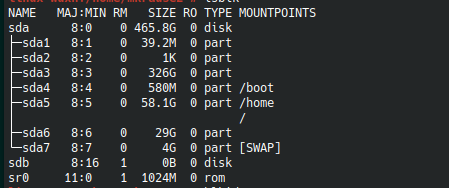

#### Results of BLKID

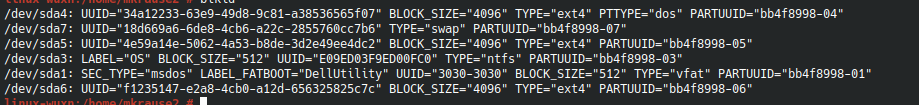

#### Filesystem inspection (cat /etc/fstab)

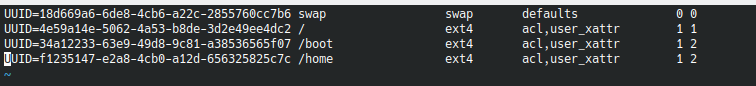

# 4. Root Cause

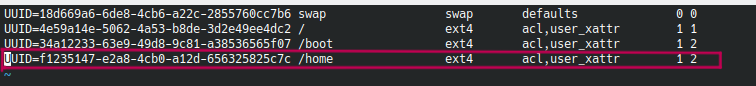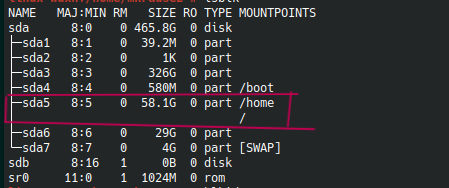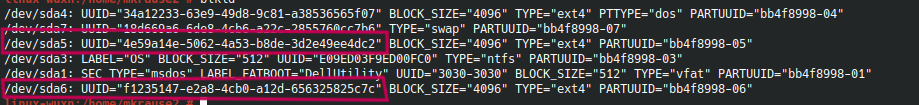

- lsblk listed sda5 as containing the / directory
- /etc/fstab was attempting to mount the / directory from sda6 rather than sda5

# 5. Resolution

- I was able to copy the UUID for /dev/sda5 into /etc/fstab
- I then replaced the incorrect UUID mounting / to the corrected UUID
- System was able to boot normally

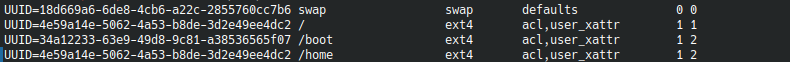
Corrected UUID

# 6. Lessons Learned

- The importance of using UUID since the /dev/sda name can change
- The importance of mount points in /etc/fstab being correct
- Using init=/bin/bash to access filesystem to edit /etc/fstab if computer cannot boot